# 🧠 Multi-Class Sentiment Classifier — Improved Version

### Negative · Neutral · Positive

**Task:** Intelligent Multi-Class Natural Language Sentiment Classification  
# 🧠 Airline Tweet Sentiment Classifier

### Multi-Class Sentiment Analysis: Negative · Neutral · Positive

**Task:** Intelligent Multi-Class Natural Language Sentiment Classification  
**Dataset:** [Twitter US Airline Sentiment](https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment)  
**Size:** 14,640 tweets (14,181 after removing duplicates)  
**Models compared:** TF-IDF + Logistic Regression (classic ML) vs fine-tuned RoBERTa (`cardiffnlp/twitter-roberta-base-sentiment-latest`)  
**Main metric:** Macro F1, because the classes are imbalanced (64 % negative, 21 % neutral, 15 % positive)  
**Result at a glance:** the fine-tuned transformer reaches macro F1 **0.829** vs **0.754** for the best classic model (Section 11)

---

## 🎯 Project Objectives

1. Build a three-class sentiment classifier for airline tweets.
2. **Measure** the effect of each preprocessing step instead of assuming it helps.
3. Compare traditional machine learning with a fine-tuned transformer on exactly the same train/test split.
4. Evaluate fairly: all decisions use cross-validation on the training set, and the test set is used only once, with bootstrap confidence intervals.
5. Understand the mistakes through label-quality checks and a structured error analysis.

## 🧪 Methodology Principles

- **No leakage:** near-duplicate tweets are removed *before* the split.
- **Split first:** every choice (preprocessing, features, model, tuning) is made on the training set only.
- **Honest comparison:** repeated stratified cross-validation (mean ± standard deviation), then a single test evaluation with 95 % bootstrap confidence intervals.
- **Reproducible:** fixed random seed (42) and portable file paths.

## 📑 Table of Contents

| No. | Section | What it does |
|:---:|---|---|
| 1 | Imports and Configuration | Libraries, constants, output folder |
| 2 | NLTK Resources | Stop-words and lemmatizer data |
| 3 | Load the Dataset and Remove Duplicates | Loads the CSV and removes near-duplicates |
| 4 | Quick EDA | Class balance, label confidence, tweet length |
| 4.1 | Train/Test Split | Stratified 80/20 split, test set locked away |
| 5 | Preprocessing | Cleaning functions that keep sentiment signals (`!`, `?`, emoticons) |
| 5.1 | Preprocessing Ablation | Cross-validated comparison of 7 preprocessing variants |
| 6 | Richer Features and Model Comparison | Word and character n-grams, airline, style features; 7 configurations |
| 7 | Hyperparameter Tuning | GridSearchCV on the best Logistic Regression |
| 8 | Final Test Evaluation | Test set used once, with confidence intervals |
| 8.1 | Neutral-Class Threshold Tuning | Class-probability weights chosen on out-of-fold predictions |
| 9 | Label Quality | Uses annotator confidence to check label noise |
| 10 | Transformer Fine-Tuning | RoBERTa fine-tuned with a class-weighted loss |
| 11 | Final Comparison | All models side by side on the test set |
| 12 | Structured Error Analysis | Auto-tagged errors, hardest complaint reasons, CSV for manual tagging |
| 13 | Save the Model and Demo | Saved model, prediction function, Gradio app |
| 14 | Results Summary | Auto-generated summary of the run |
| 15 | Conclusion | Key findings, limitations, future work |

---

## 🚀 What's New in This Version?

This version improves the baseline sentiment classifier through transformer fine-tuning, systematic experiments, better evaluation, and detailed error analysis.

| No. | Improvement | Section |
|:---:|---|:---:|
| 1 | Fine-tune a tweet-pretrained transformer and compare it with a traditional machine learning model. | 10 |
| 2 | Perform preprocessing ablation studies to measure the impact of each preprocessing step. | 5 |
| 3 | Preserve sentiment signals such as `!`, `?`, emoticons, and CAPITALIZATION; add character n-grams and airline features. | 5–6 |
| 4 | Compare models using repeated cross-validation (mean ± standard deviation). Use the test set only once and calculate bootstrap confidence intervals. | 6–8 |
| 5 | Use `airline_sentiment_confidence` and `negativereason` to investigate label quality. | 9, 12 |
| 6 | Tune the decision threshold for the Neutral class to improve classification performance. | 8 |
| 7 | Perform structured error analysis using automatic error tags and generate a CSV file for manual review. | 12 |
| 8 | Improve code quality by removing near-duplicates before splitting, eliminating unused code, and using portable file paths. | 3 |

---

### 🎯 Main Objectives

- Improve classification performance across all three sentiment classes.
- Compare traditional machine learning with transformer-based models.
- Evaluate the contribution of individual preprocessing steps.
- Reduce evaluation bias through a consistent experimental methodology.
- Understand misclassifications and identify opportunities for further improvement.

## 1. Imports and Configuration

In [1]:
import os, re, warnings
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_val_score, train_test_split)
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

RANDOM_STATE = 42
LABELS = ["negative", "neutral", "positive"]          # alphabetical = sklearn's class order
OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."

## 2. NLTK Resources

In [2]:
def nltk_ready():
    try:
        stopwords.words("english")
        WordNetLemmatizer().lemmatize("flights")
        return True
    except LookupError:
        return False

if not nltk_ready():
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)

assert nltk_ready(), "NLTK data missing. Turn Internet On (Kaggle) or run nltk.download() manually."
print("✅ NLTK ready")

✅ NLTK ready


## 3. Load the Dataset and Remove Duplicates



In [3]:
def find_tweets_csv():
    for base in ["/kaggle/input", "."]:
        for root, _, files in os.walk(base):
            if "Tweets.csv" in files:
                return os.path.join(root, "Tweets.csv")
    raise FileNotFoundError("Tweets.csv not found. Add the Kaggle dataset or place the file next to the notebook.")

DATA_PATH = find_tweets_csv()
print("Loading:", DATA_PATH)

raw = pd.read_csv(DATA_PATH)
df = raw[["text", "airline_sentiment", "airline", "airline_sentiment_confidence", "negativereason"]].rename(
    columns={"airline_sentiment": "label"})
print("Raw shape:", df.shape)

URL_RE = re.compile(r"http\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")

def dedupe_key(t):
    t = URL_RE.sub(" ", str(t).lower())
    t = MENTION_RE.sub(" ", t)
    t = re.sub(r"^\s*rt\b", " ", t)
    return re.sub(r"[^a-z0-9]+", " ", t).strip()

df["key"] = df["text"].map(dedupe_key)
before = len(df)
df = df.dropna(subset=["text", "label"])
df = df.drop_duplicates(subset="key").reset_index(drop=True)
df = df[df["key"] != ""].reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate / near-duplicate / empty tweets -> {df.shape}")
df.head()

Loading: /kaggle/input/datasets/crowdflower/twitter-airline-sentiment/Tweets.csv
Raw shape: (14640, 5)
Removed 459 duplicate / near-duplicate / empty tweets -> (14181, 6)


,text,label,airline,airline_sentiment_confidence,negativereason,key
0,@VirginAmerica What @dhepburn said.,neutral,Virgin America,1.0000,NaN,what said
1,@VirginAmerica plus you've added commercials t...,positive,Virgin America,0.3486,NaN,plus you ve added commercials to the experienc...
2,@VirginAmerica I didn't today... Must mean I n...,neutral,Virgin America,0.6837,NaN,i didn t today must mean i need to take anothe...
3,@VirginAmerica it's really aggressive to blast...,negative,Virgin America,1.0000,Bad Flight,it s really aggressive to blast obnoxious ente...
4,@VirginAmerica and it's a really big bad thing...,negative,Virgin America,1.0000,Can't Tell,and it s a really big bad thing about it


## 4. Quick EDA (class balance, label confidence, length)

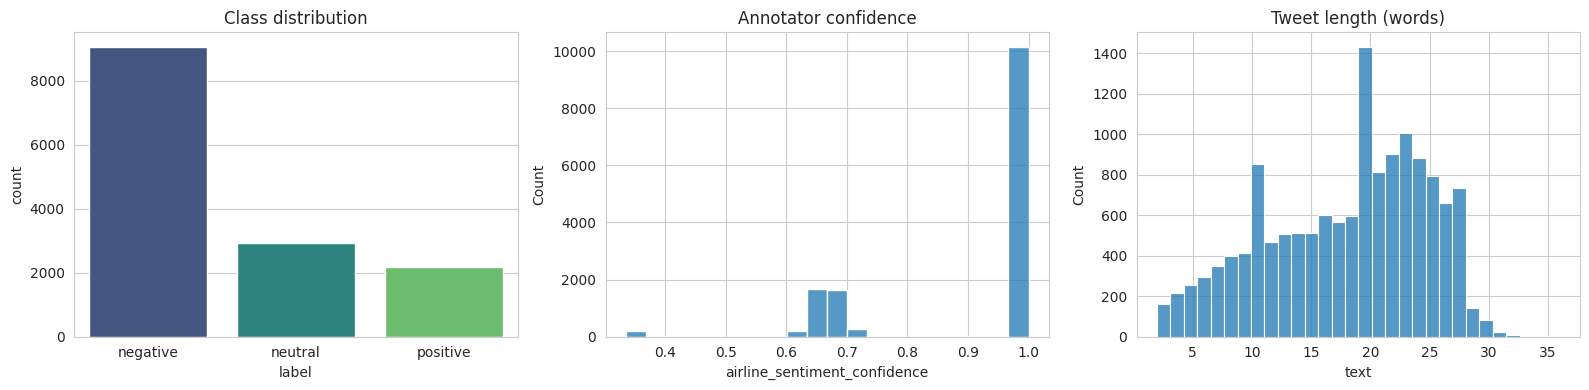

{'negative': 0.639, 'neutral': 0.207, 'positive': 0.154}
Share of tweets with confidence < 0.8 per class:
label
negative    0.194
neutral     0.503
positive    0.355
Name: low, dtype: float64


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="label", order=LABELS, palette="viridis", ax=ax[0]); ax[0].set_title("Class distribution")
sns.histplot(df["airline_sentiment_confidence"], bins=20, ax=ax[1]); ax[1].set_title("Annotator confidence")
sns.histplot(df["text"].str.split().str.len(), bins=30, ax=ax[2]); ax[2].set_title("Tweet length (words)")
plt.tight_layout(); plt.show()

print(df["label"].value_counts(normalize=True).round(3).to_dict())
print("Share of tweets with confidence < 0.8 per class:")
print(df.assign(low=df["airline_sentiment_confidence"] < 0.8).groupby("label")["low"].mean().round(3))

### 4.1 Split first, then make every decision on the training set only

The test set is touched **once**, at the end. Preprocessing choices, model choice and tuning all use cross-validation on the training portion.

In [5]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=RANDOM_STATE)
train_df, test_df = train_df.copy().reset_index(drop=True), test_df.copy().reset_index(drop=True)
y_train, y_test = train_df["label"].values, test_df["label"].values
print("Train:", len(train_df), "| Test:", len(test_df))

Train: 11344 | Test: 2837


## 5. Preprocessing: Build Variants, Then **Measure** Them


In [6]:
POS_EMOJI = "😀😃😄😁😆😊😍🥰😘👍🙏❤♥💕👏🎉😎"
NEG_EMOJI = "😡😠😤😞😢😭😒👎💔🤬😩😫😖🙄"
SIGNALS = [
    (re.compile(r"(?<![A-Za-z0-9])[:=;]'?-?[)dDpP\]](?![A-Za-z0-9])|\^_\^|<3|[" + POS_EMOJI + "]"), " emopos "),
    (re.compile(r"(?<![A-Za-z0-9])[:=;]'?-?[(\[/\\|](?![A-Za-z0-9])|>:\(|[" + NEG_EMOJI + "]"), " emoneg "),
    (re.compile(r"!+"), " exclam "),
    (re.compile(r"\?+"), " qmark "),
]

def clean_text(text, signals=True):
    t = str(text).replace("’", "'")
    t = URL_RE.sub(" ", t)
    t = MENTION_RE.sub(" ", t)
    if signals:
        for pat, tok in SIGNALS:
            t = pat.sub(tok, t)
    t = t.lower().replace("#", " ")
    t = re.sub(r"\bwon't\b", "will not", t)
    t = re.sub(r"\bcan't\b", "can not", t)
    t = re.sub(r"n't\b", " not", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

BASE_STOP = set(stopwords.words("english"))
ORIG_KEEP = {"no", "not", "nor", "never", "against"}                       # first version
NEW_KEEP = ORIG_KEEP | {"but", "however", "very", "too", "only", "more", "most", "again", "than"}
STOP_ORIG = BASE_STOP - ORIG_KEEP
STOP_NEW = BASE_STOP - NEW_KEEP

def remove_stop(text, stop):
    return " ".join(t for t in text.split() if t not in stop and len(t) > 1)

_lemmatizer = WordNetLemmatizer()
@lru_cache(maxsize=None)
def lemma_word(w):
    return _lemmatizer.lemmatize(_lemmatizer.lemmatize(w, "n"), "v")

def lemmatize(text):
    return " ".join(lemma_word(w) for w in text.split())

def light_clean(text):
    # minimal clean used for character n-grams: no URLs / mentions, lower-case, punctuation kept
    return re.sub(r"\s+", " ", MENTION_RE.sub(" ", URL_RE.sub(" ", str(text)))).strip().lower()

sample = "@united Worst flight EVER!!! Delayed 3 hours and they didn't help :( http://t.co/xyz #fail"
print("Original :", sample)
print("Cleaned  :", clean_text(sample))
print("Full     :", lemmatize(remove_stop(clean_text(sample), STOP_NEW)))

Original : @united Worst flight EVER!!! Delayed 3 hours and they didn't help :( http://t.co/xyz #fail
Cleaned  : worst flight ever exclam delayed hours and they did not help emoneg fail
Full     : worst flight ever exclam delay hour not help emoneg fail


### 5.1 Ablation: which preprocessing really helps?



,mean,std
A raw (lower-case only),0.7349,0.0122
B cleaned (no signals),0.7371,0.0102
C cleaned + signals (! ? emoticons),0.7478,0.0059
D C + original stop-words,0.7337,0.0096
E C + smaller stop list,0.7344,0.0071
F E + lemmatization,0.7422,0.0051
G first-version pipeline,0.7159,0.0033


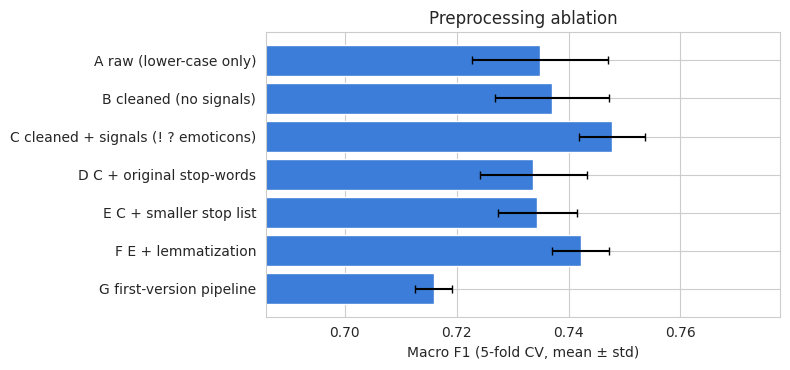

In [7]:
VARIANTS = {
    "A raw (lower-case only)":                 lambda s: s.str.lower(),
    "B cleaned (no signals)":                  lambda s: s.apply(clean_text, signals=False),
    "C cleaned + signals (! ? emoticons)":     lambda s: s.apply(clean_text),
    "D C + original stop-words":               lambda s: s.apply(clean_text).apply(remove_stop, stop=STOP_ORIG),
    "E C + smaller stop list":                 lambda s: s.apply(clean_text).apply(remove_stop, stop=STOP_NEW),
    "F E + lemmatization":                     lambda s: s.apply(clean_text).apply(remove_stop, stop=STOP_NEW).apply(lemmatize),
    "G first-version pipeline":                lambda s: s.apply(clean_text, signals=False).apply(remove_stop, stop=STOP_ORIG).apply(lemmatize),
}

def tfidf_lr():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
abl_scores = {}
for name, fn in VARIANTS.items():
    Xv = fn(train_df["text"])
    abl_scores[name] = cross_val_score(tfidf_lr(), Xv, y_train, cv=cv5, scoring="f1_macro", n_jobs=-1)

abl_df = pd.DataFrame({n: {"mean": s.mean(), "std": s.std()} for n, s in abl_scores.items()}).T.round(4)
display(abl_df)

plt.figure(figsize=(8, 3.8))
plt.barh(abl_df.index[::-1], abl_df["mean"][::-1], xerr=abl_df["std"][::-1], color="#3b7dd8", capsize=3)
plt.xlim(abl_df["mean"].min() - 0.03, abl_df["mean"].max() + 0.03)
plt.xlabel("Macro F1 (5-fold CV, mean ± std)"); plt.title("Preprocessing ablation"); plt.tight_layout(); plt.show()

In [8]:
# Choose the preprocessing by CV mean. Differences smaller than ~1 std are noise: in that case
# prefer a simpler variant by setting PREPROCESS_OVERRIDE to its name.
PREPROCESS_OVERRIDE = None
best_variant = PREPROCESS_OVERRIDE or abl_df["mean"].idxmax()
print("Selected preprocessing:", best_variant)

for d in (train_df, test_df):                      # preprocessing is stateless, so applying it to test is leak-free
    d["proc"] = VARIANTS[best_variant](d["text"])
    d["light"] = d["text"].map(light_clean)

FEATURE_COLS = ["text", "proc", "light", "airline"]
X_train, X_test = train_df[FEATURE_COLS], test_df[FEATURE_COLS]
train_df[["text", "proc", "label"]].head(6)

Selected preprocessing: C cleaned + signals (! ? emoticons)


,text,proc,label
0,@USAirways US 728/Feb 21. Arrive 7 hrs Late Fl...,us feb arrive hrs late flight checked car seat...,negative
1,@JetBlue don't think any1 rly knows what's goi...,do not think any rly knows what s goin on supp...,negative
2,@USAirways what happens to frequent flyer mile...,what happens to frequent flyer miles earned on...,neutral
3,@united negative. Done wasting time with amate...,negative done wasting time with amateurs at cu...,negative
4,@USAirways hey folks where do you hide luggage...,hey folks where do you hide luggage when you c...,negative
5,@united feeling poor on the church-mouse level...,feeling poor on the church mouse level here do...,negative


## 6. Richer Features and Fair Model Comparison

Feature blocks (each can be switched on or off):
- **word**: TF-IDF of word 1-2 grams (from the selected preprocessing)
- **char**: TF-IDF of character 2-5 grams (`char_wb`), robust to typos and slang such as *thx*, *omg*
- **airline**: one-hot airline (some airlines have a higher base rate of complaints)
- **extra**: count of `!`, count of `?`, share of ALL-CAPS words, tweet length, presence of `...`

Every model is scored with **repeated 5-fold CV (2 repeats) on the training set**, so we can report mean ± std and stop picking winners from noise.

✓ LR  | word                 macro F1 = 0.7492 ± 0.0073
✓ SVM | word                 macro F1 = 0.7475 ± 0.0126
✓ CNB | word                 macro F1 = 0.6882 ± 0.0112
✓ LR  | word+char            macro F1 = 0.7624 ± 0.0104
✓ LR  | word+char+airline    macro F1 = 0.7598 ± 0.0093
✓ LR  | all features         macro F1 = 0.7578 ± 0.0103


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

✓ SVM | all features         macro F1 = 0.7483 ± 0.0138


,mean,std
LR | word,0.7492,0.0073
SVM | word,0.7475,0.0126
CNB | word,0.6882,0.0112
LR | word+char,0.7624,0.0104
LR | word+char+airline,0.7598,0.0093
LR | all features,0.7578,0.0103
SVM | all features,0.7483,0.0138


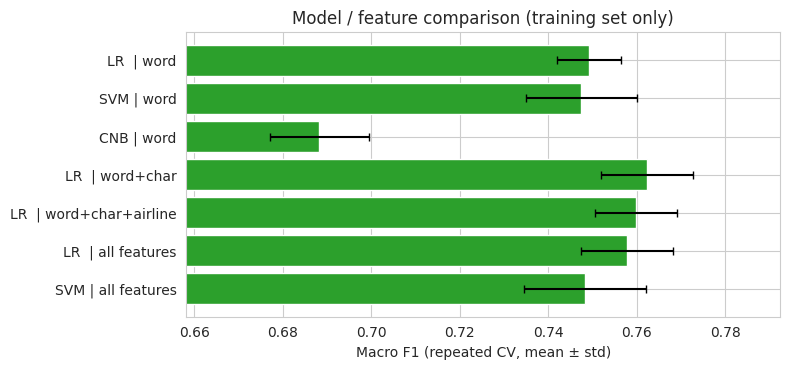

In [9]:
def extra_feats(texts):
    rows = []
    for t in texts:
        t = MENTION_RE.sub(" ", URL_RE.sub(" ", str(t)))
        words = re.findall(r"[A-Za-z]+", t)
        caps = sum(1 for w in words if len(w) > 2 and w.isupper())
        rows.append([t.count("!"), t.count("?"), caps / max(len(words), 1), len(words), int("..." in t)])
    return np.array(rows, dtype=float)

def build_pipe(clf="lr", char=False, airline=False, extra=False, C=1.0):
    parts = [("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), "proc")]
    if char:
        parts.append(("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                                              sublinear_tf=True, max_features=100000), "light"))
    if airline:
        parts.append(("airline", OneHotEncoder(handle_unknown="ignore"), ["airline"]))
    if extra:
        parts.append(("extra", Pipeline([("f", FunctionTransformer(extra_feats)),
                                         ("s", StandardScaler(with_mean=False))]), "text"))
    feats = ColumnTransformer(parts, sparse_threshold=1.0)
    if clf == "lr":
        model = LogisticRegression(C=C, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
    elif clf == "svm":
        model = LinearSVC(C=C, class_weight="balanced", random_state=RANDOM_STATE)
    else:
        model = ComplementNB()
    return Pipeline([("feats", feats), ("clf", model)])

configs = {
    "LR  | word":                      dict(clf="lr"),
    "SVM | word":                      dict(clf="svm"),
    "CNB | word":                      dict(clf="cnb"),
    "LR  | word+char":                 dict(clf="lr", char=True),
    "LR  | word+char+airline":         dict(clf="lr", char=True, airline=True),
    "LR  | all features":              dict(clf="lr", char=True, airline=True, extra=True),
    "SVM | all features":              dict(clf="svm", char=True, airline=True, extra=True),
}

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
cv_scores = {}
for name, cfg in configs.items():
    cv_scores[name] = cross_val_score(build_pipe(**cfg), X_train, y_train, cv=rcv, scoring="f1_macro", n_jobs=-1)
    print(f"✓ {name:<26} macro F1 = {cv_scores[name].mean():.4f} ± {cv_scores[name].std():.4f}")

cv_df = pd.DataFrame({n: {"mean": s.mean(), "std": s.std()} for n, s in cv_scores.items()}).T.round(4)
display(cv_df)
plt.figure(figsize=(8, 3.8))
plt.barh(cv_df.index[::-1], cv_df["mean"][::-1], xerr=cv_df["std"][::-1], color="#2ca02c", capsize=3)
plt.xlim(cv_df["mean"].min() - 0.03, cv_df["mean"].max() + 0.03)
plt.xlabel("Macro F1 (repeated CV, mean ± std)"); plt.title("Model / feature comparison (training set only)")
plt.tight_layout(); plt.show()

## 7. Hyperparameter Tuning (best Logistic Regression feature set)

We tune the best **Logistic Regression** configuration (needed later for probabilities) with 5-fold CV on the training set.
Note that `best_score_` is slightly optimistic because the same folds select the winner, so we keep the tuned model only if it beats the untuned one by more than one standard deviation.

In [10]:
lr_names = [n for n in configs if n.startswith("LR")]
best_lr_name = cv_df.loc[lr_names, "mean"].idxmax()
base_cfg = configs[best_lr_name]
print("Best untuned LR configuration:", best_lr_name)

param_grid = {
    "feats__word__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "clf__C": [0.3, 1, 3, 10],
}
grid = GridSearchCV(build_pipe(**base_cfg), param_grid, scoring="f1_macro", cv=cv5, n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

untuned_mean, untuned_std = cv_df.loc[best_lr_name, ["mean", "std"]]
gain = grid.best_score_ - untuned_mean
print("Best params          :", grid.best_params_)
print(f"Tuned CV macro F1    : {grid.best_score_:.4f}")
print(f"Untuned CV macro F1  : {untuned_mean:.4f} ± {untuned_std:.4f}")
print(f"Gain from tuning     : {gain:+.4f}")

if gain > untuned_std:
    final_classic = grid.best_estimator_
    print("→ Tuning gives a real gain; using the tuned model.")
else:
    final_classic = build_pipe(**base_cfg).fit(X_train, y_train)
    print("→ Gain is within noise; keeping the simpler untuned model.")

Best untuned LR configuration: LR  | word+char
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best params          : {'clf__C': 1, 'feats__word__ngram_range': (1, 2)}
Tuned CV macro F1    : 0.7609
Untuned CV macro F1  : 0.7624 ± 0.0104
Gain from tuning     : -0.0015
→ Gain is within noise; keeping the simpler untuned model.


## 8. Final Test Evaluation (test set used once) with Confidence Intervals

Macro F1 is reported with a **95 % bootstrap confidence interval**. If two models' intervals overlap heavily, their difference is not trustworthy.

Classic ML | accuracy 0.8051 | macro F1 0.7538  (95% CI 0.735 to 0.772)

              precision    recall  f1-score   support

    negative     0.9057    0.8527    0.8784      1813
     neutral     0.6150    0.6968    0.6534       587
    positive     0.7075    0.7529    0.7295       437

    accuracy                         0.8051      2837
   macro avg     0.7427    0.7675    0.7538      2837
weighted avg     0.8150    0.8051    0.8089      2837



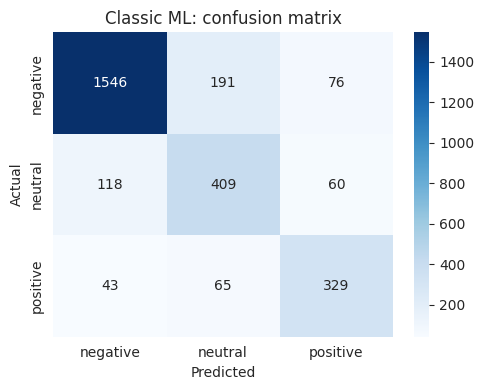

In [11]:
def bootstrap_macro_f1(y_true, y_pred, n_boot=1000, seed=RANDOM_STATE):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        out.append(f1_score(y_true[idx], y_pred[idx], average="macro"))
    return np.percentile(out, [2.5, 97.5])

def paired_bootstrap_diff(y_true, pred_a, pred_b, n_boot=1000, seed=RANDOM_STATE):
    # 95% CI of (macro F1 of B) - (macro F1 of A) on the same resampled tweets
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        d.append(f1_score(y_true[idx], pred_b[idx], average="macro") - f1_score(y_true[idx], pred_a[idx], average="macro"))
    return np.percentile(d, [2.5, 97.5])

test_preds = {}
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
test_preds["Majority baseline"] = dummy.predict(X_test)
test_preds["Classic ML (final)"] = final_classic.predict(X_test)

lo, hi = bootstrap_macro_f1(y_test, test_preds["Classic ML (final)"])
print(f"Classic ML | accuracy {accuracy_score(y_test, test_preds['Classic ML (final)']):.4f} | "
      f"macro F1 {f1_score(y_test, test_preds['Classic ML (final)'], average='macro'):.4f}  (95% CI {lo:.3f} to {hi:.3f})\n")
print(classification_report(y_test, test_preds["Classic ML (final)"], labels=LABELS, digits=4))

cm = confusion_matrix(y_test, test_preds["Classic ML (final)"], labels=LABELS)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
plt.title("Classic ML: confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.tight_layout(); plt.show()

### 8.1 Tuning the decision for the weak class (neutral)

The neutral class has the lowest F1. Instead of always taking the arg-max probability, we multiply the class probabilities by weights and pick the weights that maximise macro F1 on **out-of-fold predictions from the training set**. The test set only checks the result once.

In [12]:
oof_proba = cross_val_predict(clone(final_classic), X_train, y_train, cv=cv5, method="predict_proba", n_jobs=-1)
classes = np.array(final_classic.classes_)

best = (1.0, 1.0, f1_score(y_train, classes[oof_proba.argmax(1)], average="macro"))
for w_neu in np.arange(0.7, 1.61, 0.1):
    for w_pos in np.arange(0.7, 1.61, 0.1):
        w = np.array([1.0, w_neu, w_pos])
        s = f1_score(y_train, classes[(oof_proba * w).argmax(1)], average="macro")
        if s > best[2] + 1e-9:
            best = (round(w_neu, 2), round(w_pos, 2), s)

class_weights_vec = np.array([1.0, best[0], best[1]])
print(f"Chosen class weights (neg, neu, pos): {class_weights_vec}  | OOF macro F1 = {best[2]:.4f}")

test_proba = final_classic.predict_proba(X_test)
test_preds["Classic ML + tuned thresholds"] = classes[(test_proba * class_weights_vec).argmax(1)]
for k in ["Classic ML (final)", "Classic ML + tuned thresholds"]:
    print(f"{k:<32} test macro F1 = {f1_score(y_test, test_preds[k], average='macro'):.4f}")

Chosen class weights (neg, neu, pos): [1.  0.8 0.9]  | OOF macro F1 = 0.7627
Classic ML (final)               test macro F1 = 0.7538
Classic ML + tuned thresholds    test macro F1 = 0.7590


## 9. Label Quality: Use the Annotator Confidence

`airline_sentiment_confidence` is the agreement between annotators. Low values mean the **label itself is doubtful** (many are neutral or mixed tweets). Two checks:
1. How well does the model do on tweets with reliable labels?
2. Does training only on reliable labels help?

Both are diagnostics (not used to choose the final model, to keep the test set clean).

In [13]:
CONF = 0.8
hc_train = (train_df["airline_sentiment_confidence"] >= CONF).values
hc_test = (test_df["airline_sentiment_confidence"] >= CONF).values
print(f"High-confidence tweets: train {hc_train.mean():.1%}, test {hc_test.mean():.1%}")

pred = test_preds["Classic ML (final)"]
m_filtered = clone(final_classic).fit(X_train[hc_train], y_train[hc_train])
pred_f = m_filtered.predict(X_test)

rows = [
    ("Trained on all labels",         "all test tweets",       f1_score(y_test, pred, average="macro")),
    ("Trained on all labels",         f"test conf ≥ {CONF}",   f1_score(y_test[hc_test], pred[hc_test], average="macro")),
    (f"Trained on conf ≥ {CONF} only", "all test tweets",       f1_score(y_test, pred_f, average="macro")),
    (f"Trained on conf ≥ {CONF} only", f"test conf ≥ {CONF}",   f1_score(y_test[hc_test], pred_f[hc_test], average="macro")),
]
display(pd.DataFrame(rows, columns=["Training data", "Evaluated on", "Macro F1"]).round(4))
print("Per-class F1 on reliable test labels (trained on all labels):")
print(classification_report(y_test[hc_test], pred[hc_test], labels=LABELS, digits=4))

High-confidence tweets: train 72.0%, test 70.3%


,Training data,Evaluated on,Macro F1
0,Trained on all labels,all test tweets,0.7538
1,Trained on all labels,test conf ≥ 0.8,0.8471
2,Trained on conf ≥ 0.8 only,all test tweets,0.7537
3,Trained on conf ≥ 0.8 only,test conf ≥ 0.8,0.8520


Per-class F1 on reliable test labels (trained on all labels):
              precision    recall  f1-score   support

    negative     0.9567    0.9100    0.9328      1433
     neutral     0.7045    0.8110    0.7540       291
    positive     0.8169    0.8959    0.8546       269

    accuracy                         0.8936      1993
   macro avg     0.8260    0.8723    0.8471      1993
weighted avg     0.9010    0.8936    0.8961      1993



## 10. Fine-Tune a Tweet-Pretrained Transformer

`cardiffnlp/twitter-roberta-base-sentiment-latest` is RoBERTa pretrained on tweets and already used for 3-class sentiment (negative / neutral / positive). We **fine-tune it on our training split** (10 % of it is held out for model selection, the test set stays untouched) with a class-weighted loss.

- Runs only when a **GPU** is available (Kaggle: Accelerator → GPU T4, Internet → On). Otherwise `tx_pred` stays `None` and the later tables skip it.
- Raw tweets are used (no stop-word removal or lemmatization; transformers need the full sentence). As in the model's own recipe, mentions → `@user` and links → `http`.
- Needs `transformers` and `accelerate` (preinstalled on Kaggle; otherwise run `pip install transformers accelerate`).

In [15]:
tx_pred = None
try:
    import torch
    RUN_TRANSFORMER = torch.cuda.is_available()
except ImportError:
    RUN_TRANSFORMER = False
print("Transformer fine-tuning enabled:", RUN_TRANSFORMER)

if RUN_TRANSFORMER:
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                              DataCollatorWithPadding, Trainer, TrainingArguments, set_seed)
    set_seed(RANDOM_STATE)

    MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"
    label2id = {l: i for i, l in enumerate(LABELS)}
    id2label = {i: l for l, i in label2id.items()}

    def prep_tweet(t):
        return " ".join("@user" if w.startswith("@") and len(w) > 1 else "http" if w.startswith("http") else w
                        for w in str(t).split())

    tok = AutoTokenizer.from_pretrained(MODEL_NAME)

    class TweetDS(torch.utils.data.Dataset):
        def __init__(self, texts, labels=None):
            self.enc = tok([prep_tweet(t) for t in texts], truncation=True, max_length=96)
            self.labels = None if labels is None else [label2id[l] for l in labels]
        def __len__(self):
            return len(self.enc["input_ids"])
        def __getitem__(self, i):
            item = {k: v[i] for k, v in self.enc.items()}
            if self.labels is not None:
                item["labels"] = self.labels[i]
            return item

    tr_idx, val_idx = train_test_split(np.arange(len(train_df)), test_size=0.1, stratify=y_train, random_state=RANDOM_STATE)
    ds_train = TweetDS(train_df["text"].values[tr_idx], y_train[tr_idx])
    ds_val = TweetDS(train_df["text"].values[val_idx], y_train[val_idx])
    ds_test = TweetDS(test_df["text"].values)

    counts = np.bincount([label2id[l] for l in y_train[tr_idx]], minlength=3)
    cls_w = torch.tensor(len(tr_idx) / (3 * counts), dtype=torch.float)

    class WeightedTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop("labels")
            outputs = model(**inputs)
            loss = torch.nn.functional.cross_entropy(outputs.logits, labels, weight=cls_w.to(outputs.logits.device))
            return (loss, outputs) if return_outputs else loss

    def compute_metrics(p):
        preds = p.predictions.argmax(-1)
        return {"macro_f1": f1_score(p.label_ids, preds, average="macro"),
                "accuracy": accuracy_score(p.label_ids, preds)}

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=3, id2label=id2label, label2id=label2id, ignore_mismatched_sizes=True)

    # warmup_steps / eval-argument name are chosen to work across old and new transformers versions
    import inspect, math
    BATCH, EPOCHS = 32, 3
    warmup_steps = int(0.1 * EPOCHS * math.ceil(len(ds_train) / BATCH))

    args_kw = dict(output_dir=os.path.join(OUT_DIR, "tx_runs"), num_train_epochs=EPOCHS,
                   per_device_train_batch_size=BATCH, per_device_eval_batch_size=64,
                   learning_rate=2e-5, weight_decay=0.01, warmup_steps=warmup_steps,
                   save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="macro_f1",
                   greater_is_better=True, save_total_limit=1, fp16=True, seed=RANDOM_STATE,
                   report_to="none", logging_steps=50)
    ta_params = inspect.signature(TrainingArguments.__init__).parameters
    args_kw["eval_strategy" if "eval_strategy" in ta_params else "evaluation_strategy"] = "epoch"
    targs = TrainingArguments(**args_kw)

    trainer = WeightedTrainer(model=model, args=targs, train_dataset=ds_train, eval_dataset=ds_val,
                              data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)
    trainer.train()

    logits = trainer.predict(ds_test).predictions
    tx_pred = np.array(LABELS)[logits.argmax(-1)]
    test_preds["Fine-tuned transformer"] = tx_pred

    trainer.save_model(os.path.join(OUT_DIR, "sentiment_transformer"))
    tok.save_pretrained(os.path.join(OUT_DIR, "sentiment_transformer"))
    print(f"Transformer test macro F1 = {f1_score(y_test, tx_pred, average='macro'):.4f}")
    print(classification_report(y_test, tx_pred, labels=LABELS, digits=4))
else:
    print("⚠️ No GPU detected: skipping transformer fine-tuning. Re-run on a GPU session for the full comparison.")

Transformer fine-tuning enabled: True


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.466820,0.432255,0.795048,0.841410
2,0.370951,0.411499,0.839728,0.875771
3,0.259699,0.433064,0.827711,0.860793


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Transformer test macro F1 = 0.8285
              precision    recall  f1-score   support

    negative     0.9344    0.9117    0.9229      1813
     neutral     0.7224    0.7359    0.7291       587
    positive     0.8043    0.8650    0.8335       437

    accuracy                         0.8682      2837
   macro avg     0.8204    0.8376    0.8285      2837
weighted avg     0.8705    0.8682    0.8691      2837



## 11. Final Comparison on the Test Set

,Accuracy,Macro F1,CI low,CI high,F1 negative,F1 neutral,F1 positive
Model,,,,,,,
Majority baseline,0.6391,0.2599,0.2551,0.2643,0.7798,0.0000,0.0000
Classic ML (final),0.8051,0.7538,0.7349,0.7717,0.8784,0.6534,0.7295
Classic ML + tuned thresholds,0.8153,0.7590,0.7404,0.7768,0.8878,0.6616,0.7275
Fine-tuned transformer,0.8682,0.8285,0.8112,0.8438,0.9229,0.7291,0.8335


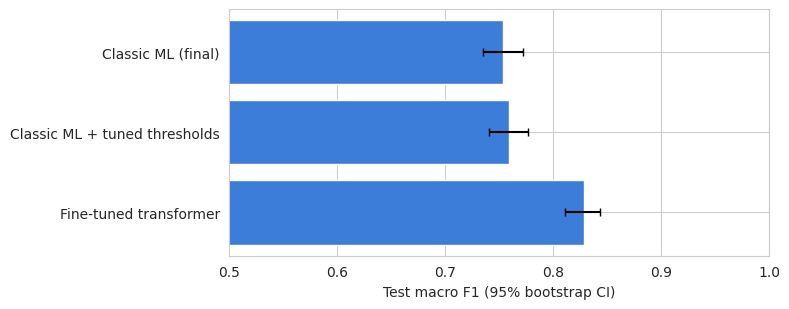

Transformer minus classic macro F1: 95% CI [+0.059, +0.092]  (significant)
Best model on the test set: Fine-tuned transformer


In [16]:
rows = []
for name, p in test_preds.items():
    lo, hi = bootstrap_macro_f1(y_test, p)
    f1s = f1_score(y_test, p, average=None, labels=LABELS, zero_division=0)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, p),
                 "Macro F1": f1_score(y_test, p, average="macro"), "CI low": lo, "CI high": hi,
                 **{f"F1 {l}": v for l, v in zip(LABELS, f1s)}})
results_df = pd.DataFrame(rows).set_index("Model").round(4)
display(results_df)

plot_df = results_df.drop(index="Majority baseline")
plt.figure(figsize=(8, 3.2))
err = np.vstack([plot_df["Macro F1"] - plot_df["CI low"], plot_df["CI high"] - plot_df["Macro F1"]])
plt.barh(plot_df.index[::-1], plot_df["Macro F1"][::-1], xerr=err[:, ::-1], color="#3b7dd8", capsize=3)
plt.xlim(0.5, 1.0); plt.xlabel("Test macro F1 (95% bootstrap CI)"); plt.tight_layout(); plt.show()

if tx_pred is not None:
    d_lo, d_hi = paired_bootstrap_diff(y_test, test_preds["Classic ML (final)"], tx_pred)
    print(f"Transformer minus classic macro F1: 95% CI [{d_lo:+.3f}, {d_hi:+.3f}]  "
          f"({'significant' if d_lo > 0 or d_hi < 0 else 'not significant'})")

best_key = results_df.drop(index="Majority baseline")["Macro F1"].idxmax()
best_pred = np.asarray(test_preds[best_key])
print("Best model on the test set:", best_key)

## 12. Structured Error Analysis

Instead of reading eight random mistakes, we (1) auto-tag every error with simple linguistic and data-quality cues, (2) count the tags, (3) check which complaint reasons are hardest, and (4) export a sample to **hand-tag** in a spreadsheet.
The auto-tags are heuristics, so treat the counts as a first look and confirm with the manual sample.

In [17]:
errs = test_df.assign(pred=best_pred)
errs = errs[errs["label"] != errs["pred"]].copy()
print(f"Misclassified: {len(errs)} of {len(test_df)} ({len(errs)/len(test_df):.1%}) by '{best_key}'")

NEG_RE = re.compile(r"\b(not|no|never|nothing|cannot|can't|won't|don't|didn't|isn't|wasn't)\b", re.I)
CONTRAST_RE = re.compile(r"\b(but|however|although|though|yet|except)\b", re.I)
SARCASM_RE = re.compile(r"(yeah right|oh great|thanks for nothing|love how|just great|so great|nice job|way to go|\bgreat\b.*\.\.\.|\bthanks\b.*\.\.\.)", re.I)
THANKS_RE = re.compile(r"\b(thanks|thank you|thx|appreciate)\b", re.I)

def auto_tags(r):
    t, tags = r["text"], []
    if r["airline_sentiment_confidence"] < 0.7:                      tags.append("low label confidence")
    if CONTRAST_RE.search(t):                                         tags.append("mixed / contrast")
    if NEG_RE.search(t):                                              tags.append("negation")
    if SARCASM_RE.search(t) or (THANKS_RE.search(t) and r["label"] == "negative"):
                                                                      tags.append("possible sarcasm / polite complaint")
    if r["label"] == "neutral" and ("?" in t):                        tags.append("question / factual")
    if len(t.split()) <= 6:                                           tags.append("very short")
    return tags or ["no tag"]

errs["auto_tags"] = [auto_tags(r) for _, r in errs.iterrows()]   # list-comprehension also works if there are no errors
tag_counts = Counter(tag for tags in errs["auto_tags"] for tag in tags)
tag_df = pd.Series(tag_counts).sort_values(ascending=False).rename("errors").to_frame()
tag_df["% of errors"] = (tag_df["errors"] / len(errs) * 100).round(1)
display(tag_df)

# confusion pairs
display(pd.crosstab(errs["label"], errs["pred"], rownames=["actual"], colnames=["predicted"]))

Misclassified: 374 of 2837 (13.2%) by 'Fine-tuned transformer'


,errors,% of errors
low label confidence,257,68.7
negation,84,22.5
no tag,61,16.3
mixed / contrast,46,12.3
very short,44,11.8
question / factual,38,10.2
possible sarcasm / polite complaint,18,4.8


predicted,negative,neutral,positive
actual,,,
negative,0,124,36
neutral,99,0,56
positive,17,42,0


,n,error_rate
negativereason,,
Can't Tell,262,0.176
Flight Booking Problems,98,0.163
Lost Luggage,139,0.137
Damaged Luggage,15,0.133
Bad Flight,127,0.110
Late Flight,342,0.061
Customer Service Issue,532,0.056
Cancelled Flight,168,0.048
Flight Attendant Complaints,94,0.032


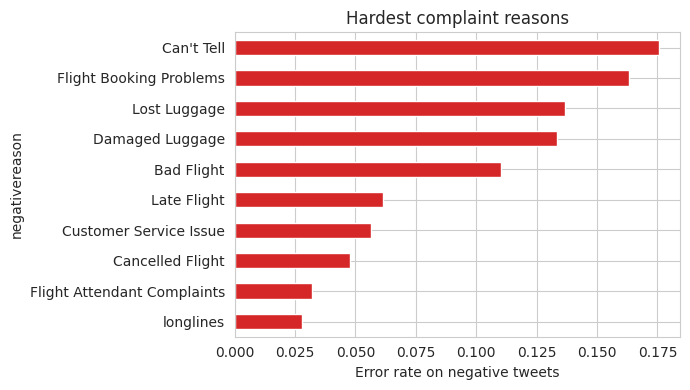

Saved 100 errors for manual tagging -> /kaggle/working/errors_to_tag.csv


,text,label,pred,airline_sentiment_confidence,negativereason,auto_tags,manual_tag
626,@USAirways your saving grace was our flight at...,negative,positive,0.7132,Can't Tell,no tag,
2484,@united Want to make my day? :) Friend is Prem...,neutral,positive,1.0000,NaN,question / factual,
2231,"@JetBlue no, they're too busy being awesome an...",positive,negative,0.6775,NaN,"low label confidence, negation",
2108,@SouthwestAir my golf bag was broken on the fl...,negative,neutral,1.0000,Damaged Luggage,no tag,
864,@united's first-class #cockup\nhttp://t.co/oh7...,negative,neutral,0.3456,Can't Tell,"low label confidence, very short",
2820,@SouthwestAir k thanks :),neutral,positive,0.6559,NaN,"low label confidence, very short",
1482,@USAirways yes - tells me the only way to mod ...,neutral,negative,0.6677,NaN,low label confidence,
2520,@SouthwestAir wow! Some things are better forg...,neutral,positive,1.0000,NaN,no tag,


In [18]:
# Which complaint reasons are hardest? (only tweets whose true label is negative)
neg_view = test_df.assign(is_err=(test_df["label"] != best_pred))
neg_view = neg_view[(neg_view["label"] == "negative") & neg_view["negativereason"].notna()]
reason_df = neg_view.groupby("negativereason")["is_err"].agg(n="count", error_rate="mean").sort_values("error_rate", ascending=False)
display(reason_df.round(3))

reason_df["error_rate"].sort_values().plot.barh(figsize=(7, 4), color="#d62728")
plt.xlabel("Error rate on negative tweets"); plt.title("Hardest complaint reasons"); plt.tight_layout(); plt.show()

# export a sample for manual tagging (fill the 'manual_tag' column in a spreadsheet)
sample_out = errs.sample(min(100, len(errs)), random_state=1)[
    ["text", "label", "pred", "airline_sentiment_confidence", "negativereason", "auto_tags"]].copy()
sample_out["auto_tags"] = sample_out["auto_tags"].map(", ".join)
sample_out["manual_tag"] = ""      # e.g. sarcasm / mixed / negation / news-like / label noise / other
csv_path = os.path.join(OUT_DIR, "errors_to_tag.csv")
sample_out.to_csv(csv_path, index=False)
print("Saved", len(sample_out), "errors for manual tagging ->", csv_path)
sample_out.head(8)

## 13. Save the Model and Predict on New Text

The classic model is saved together with the preprocessing name and the tuned class weights. Note: the saved pipeline refers to the helper function `extra_feats`, so any script that loads it must define the same function.

In [19]:
joblib.dump({"model": final_classic, "preprocess": best_variant, "class_weights": class_weights_vec},
            os.path.join(OUT_DIR, "sentiment_model.joblib"))
print("Saved ->", os.path.join(OUT_DIR, "sentiment_model.joblib"))

def predict_sentiment(texts, airlines=None):
    texts = pd.Series(list(texts))
    X = pd.DataFrame({"text": texts,
                      "proc": VARIANTS[best_variant](texts),
                      "light": texts.map(light_clean),
                      "airline": list(airlines) if airlines is not None else "unknown"})
    proba = final_classic.predict_proba(X) * class_weights_vec
    labels_ = classes[proba.argmax(1)]
    conf = (proba / proba.sum(1, keepdims=True)).max(1)
    return list(zip(labels_, conf.round(2)))

new_texts = [
    "Amazing crew, the flight was smooth and we landed early. Thank you!",
    "Lost my luggage and nobody at the desk would help. Terrible service.",
    "What time does the gate open for flight 221?",
    "Not happy with the delay, but the staff were polite.",
    "Oh great, another 3 hour delay. Thanks for nothing...",
]
for t, (p, c) in zip(new_texts, predict_sentiment(new_texts)):
    print(f"[{p:>8} {c:.2f}]  {t}")

Saved -> /kaggle/working/sentiment_model.joblib
[positive 1.00]  Amazing crew, the flight was smooth and we landed early. Thank you!
[negative 0.98]  Lost my luggage and nobody at the desk would help. Terrible service.
[ neutral 0.68]  What time does the gate open for flight 221?
[negative 0.89]  Not happy with the delay, but the staff were polite.
[negative 0.65]  Oh great, another 3 hour delay. Thanks for nothing...


In [27]:
import gradio as gr

gr.close_all()                                   # free the port if an older demo is still running

# ---------- palette ----------
FOREST, CREAM, EMERALD, BEIGE, TEXT = "#064E3B", "#FAF7F0", "#10B981", "#E7E5D9", "#292F2B"
SENT = {                                         # emoji, colour (negative/neutral are added accents: the palette has no warm tone)
    "negative": ("😠", "#B5523B"),
    "neutral":  ("😐", "#A8997A"),
    "positive": ("😊", EMERALD),
}
ORDER = ["negative", "neutral", "positive"]

AIRLINES = ["unknown"] + sorted(train_df["airline"].unique().tolist())
EXAMPLES = [
    ["@united I've been waiting 3 hours and nobody will tell me anything. Worst airline ever!!!"],
    ["@delta Thank you so much! The crew was amazing and we landed early. Best flight ever 😊"],
    ["@AmericanAir What time does the check-in counter open for flight 221 tomorrow?"],
    ["@SouthwestAir The staff were really polite, but my bag was lost and nobody could help."],
    ["@JetBlue Oh great, another cancelled flight. Thanks for nothing..."],
]

# ---------- models ----------
def classic_probs(text, airline):
    X = pd.DataFrame({"text": [text],
                      "proc": VARIANTS[best_variant](pd.Series([text])).tolist(),
                      "light": [light_clean(text)],
                      "airline": [airline]})
    p = final_classic.predict_proba(X)[0] * class_weights_vec
    p = p / p.sum()
    return {str(c): float(v) for c, v in zip(classes, p)}

tx_pipe = None                                   # fine-tuned transformer, if still in memory from section 10
try:
    from transformers import pipeline
    tx_pipe = pipeline("text-classification", model=trainer.model, tokenizer=tok, device=0, top_k=None)
except Exception as e:
    print("Transformer not available in this session -> demo will use the classic model only.", type(e).__name__)

def tx_probs(text):
    scores = tx_pipe([prep_tweet(text)])[0]
    return {d["label"].lower(): float(d["score"]) for d in scores}

MODEL_CHOICES = ["Fine-tuned transformer", "Classic ML"] if tx_pipe is not None else ["Classic ML"]

# ---------- result card ----------
PLACEHOLDER = ('<div class="card result-empty">Your result will appear here.<br>'
               'Type a tweet, or click one of the examples below the box.</div>')

def render_result(probs):
    label = max(probs, key=probs.get)
    emoji, color = SENT[label]
    bars = "".join(
        f'<div class="bar-row"><span class="bar-label">{k.capitalize()}</span>'
        f'<div class="track"><div class="fill" style="width:{probs.get(k, 0)*100:.1f}%;background:{SENT[k][1]}"></div></div>'
        f'<span class="bar-pct">{probs.get(k, 0):.0%}</span></div>' for k in ORDER)
    return (f'<div class="card"><div class="verdict-row">'
            f'<div class="badge" style="background:{color}22;border:2px solid {color}">{emoji}</div>'
            f'<div><div class="verdict" style="color:{color}">{label.capitalize()}</div>'
            f'<div class="conf">Confidence {probs[label]:.0%}</div></div></div>'
            f'<div class="bars">{bars}</div></div>')

def analyze(text, airline, model_name):
    if not text or not text.strip():
        return PLACEHOLDER
    use_tx = model_name == "Fine-tuned transformer" and tx_pipe is not None
    return render_result(tx_probs(text) if use_tx else classic_probs(text, airline))

# ---------- theme + css ----------
theme = gr.themes.Base(font=[gr.themes.GoogleFont("Inter"), "system-ui", "sans-serif"]).set(
    body_background_fill=CREAM, body_background_fill_dark=CREAM,
    body_text_color=TEXT, body_text_color_dark=TEXT,
    block_background_fill="#FFFFFF", block_background_fill_dark="#FFFFFF",
    block_border_color=BEIGE, block_border_color_dark=BEIGE,
    block_label_text_color=FOREST, block_label_text_color_dark=FOREST,
    block_title_text_color=FOREST, block_title_text_color_dark=FOREST,
    input_background_fill=CREAM, input_background_fill_dark=CREAM,
    input_border_color=BEIGE, input_border_color_dark=BEIGE,
    input_border_color_focus=EMERALD, input_border_color_focus_dark=EMERALD,
    button_primary_background_fill=FOREST, button_primary_background_fill_dark=FOREST,
    button_primary_background_fill_hover=EMERALD, button_primary_background_fill_hover_dark=EMERALD,
    button_primary_text_color="#FFFFFF", button_primary_text_color_dark="#FFFFFF",
    button_primary_border_color=FOREST, button_primary_border_color_dark=FOREST,
    checkbox_label_background_fill=CREAM, checkbox_label_background_fill_dark=CREAM,
    checkbox_label_background_fill_selected=FOREST, checkbox_label_background_fill_selected_dark=FOREST,
    checkbox_label_text_color_selected="#FFFFFF", checkbox_label_text_color_selected_dark="#FFFFFF",
    checkbox_background_color_selected=EMERALD, checkbox_background_color_selected_dark=EMERALD,
    table_even_background_fill="#FFFFFF", table_even_background_fill_dark="#FFFFFF",
    table_odd_background_fill=CREAM, table_odd_background_fill_dark=CREAM,
    table_row_focus=BEIGE, table_row_focus_dark=BEIGE,
)

CSS = f"""
.gradio-container {{ background:{CREAM} !important; max-width:1050px !important; margin:0 auto !important; }}
footer {{ display:none !important; }}
.hero {{ background:linear-gradient(135deg,{FOREST} 0%,#0A6B51 100%); border-radius:20px; padding:30px 34px; margin:0 -12px 6px; }}
.hero b {{ color:#fff; }}
.hero h1 {{ color:{CREAM}; margin:0 0 8px; font-size:2.1rem; font-weight:700; letter-spacing:-0.5px; }}
.hero p  {{ color:{BEIGE}; margin:0; font-size:1.02rem; line-height:1.5; }}
.hero .pill {{ display:inline-block; background:{EMERALD}; color:#fff; border-radius:999px; padding:3px 12px; font-size:.78rem; font-weight:600; margin-bottom:12px; }}
.card {{ background:#fff; border:1px solid {BEIGE}; border-radius:18px; padding:24px; color:{TEXT}; }}
.result-empty {{ text-align:center; color:#6b7280; padding:48px 24px; line-height:1.7; border-style:dashed; }}
.verdict-row {{ display:flex; align-items:center; gap:18px; margin-bottom:22px; }}
.badge {{ width:64px; height:64px; border-radius:50%; display:flex; align-items:center; justify-content:center; font-size:2rem; }}
.verdict {{ font-size:1.9rem; font-weight:700; line-height:1.1; }}
.conf {{ color:#5b6660; margin-top:4px; font-size:.95rem; }}
.bar-row {{ display:flex; align-items:center; gap:12px; margin:12px 0; }}
.bar-label {{ width:74px; font-size:.9rem; color:{FOREST}; font-weight:600; }}
.track {{ flex:1; height:12px; background:{BEIGE}; border-radius:999px; overflow:hidden; }}
.fill {{ height:100%; border-radius:999px; transition:width .5s ease; }}
.bar-pct {{ width:44px; text-align:right; font-variant-numeric:tabular-nums; font-size:.9rem; color:{TEXT}; }}
.foot {{ text-align:center; color:#6b7280; font-size:.82rem; padding:14px 0 4px; }}
"""

HERO = ('<div class="hero"><span class="pill">NLP · Sentiment Analysis</span>'
        '<h1>✈️ Airline Tweet Sentiment</h1>'
        '<p>Paste a tweet about an airline and the model tells you whether it is '
        '<b>negative</b>, <b>neutral</b> or <b>positive</b>, with the probability of each class.</p></div>')
FOOT = '<div class="foot">Saba Khalil</div>'

# ---------- layout (works on Gradio 4/5 and 6) ----------
GR6 = int(gr.__version__.split(".")[0]) >= 6
blocks_kw = {} if GR6 else dict(theme=theme, css=CSS)
launch_kw = dict(share=True, **(dict(theme=theme, css=CSS) if GR6 else {}))

with gr.Blocks(title="Airline Tweet Sentiment", **blocks_kw) as demo:
    gr.HTML(HERO)
    with gr.Row(equal_height=False):
        with gr.Column(scale=3):
            text = gr.Textbox(label="Tweet", lines=5, placeholder="@airline my flight was delayed again…")
            with gr.Row():
                model_name = gr.Radio(MODEL_CHOICES, value=MODEL_CHOICES[0], label="Model")
                airline = gr.Dropdown(AIRLINES, value="unknown", label="Airline (classic model only)")
            btn = gr.Button("Analyze sentiment", variant="primary", size="lg")
        with gr.Column(scale=2):
            result = gr.HTML(PLACEHOLDER)
    gr.Examples(EXAMPLES, inputs=[text], label="Try an example")
    gr.HTML(FOOT)
    btn.click(analyze, [text, airline, model_name], result)
    text.submit(analyze, [text, airline, model_name], result)

demo.launch(**launch_kw)

Closing server running on port: 7860
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://d6f38c999a1834a2da.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 14. Results Summary (auto-generated from this run)

In [25]:
print("Preprocessing selected  :", best_variant)
print("Best CV configuration   :", cv_df["mean"].idxmax(), f"(macro F1 {cv_df['mean'].max():.4f})")
print("Final classic model     :", best_lr_name, "| tuned" if final_classic is grid.best_estimator_ else "| untuned")
print()
display(results_df[["Accuracy", "Macro F1", "CI low", "CI high"]])
print("Top error tags:", ", ".join(f"{t} ({c})" for t, c in tag_counts.most_common(4)))

Preprocessing selected  : C cleaned + signals (! ? emoticons)
Best CV configuration   : LR  | word+char (macro F1 0.7624)
Final classic model     : LR  | word+char | untuned



,Accuracy,Macro F1,CI low,CI high
Model,,,,
Majority baseline,0.6391,0.2599,0.2551,0.2643
Classic ML (final),0.8051,0.7538,0.7349,0.7717
Classic ML + tuned thresholds,0.8153,0.7590,0.7404,0.7768
Fine-tuned transformer,0.8682,0.8285,0.8112,0.8438


Top error tags: low label confidence (257), negation (84), no tag (61), mixed / contrast (46)


## 15. Conclusion

This project built a three-class sentiment classifier for airline tweets and compared a classic TF-IDF + Logistic Regression pipeline with a fine-tuned tweet-pretrained RoBERTa. **The fine-tuned transformer was clearly the best model**, and the analysis shows that a large part of the remaining error comes from noisy labels rather than model weakness.

| Model | Accuracy | Macro F1 | 95 % CI |
|---|:---:|:---:|:---:|
| Majority baseline | 0.639 | 0.260 | 0.255 to 0.264 |
| Classic ML (LR, word + char n-grams) | 0.805 | 0.754 | 0.735 to 0.772 |
| Classic ML + tuned class weights | 0.815 | 0.759 | 0.740 to 0.777 |
| **Fine-tuned RoBERTa** | **0.868** | **0.829** | **0.811 to 0.844** |

### 15.1 Key Findings

1. **Preprocessing (Section 5.1).** Cleaning plus sentiment signals (variant C) scored best, with CV macro F1 **0.7478 ± 0.0059**, compared with 0.7159 ± 0.0033 for the baseline pipeline (variant G: cleaning without signals, standard stop-words, lemmatization), a gain of +0.032. Stop-word removal *lowered* the score (0.7337 and 0.7344 vs 0.7478), and lemmatization recovered only part of the loss (0.7422). Keeping `!`, `?` and emoticons gave a small gain over cleaning without them (0.7371 → 0.7478, about one standard deviation).
2. **Features and models (Section 6).** Adding character n-grams improved Logistic Regression from 0.7492 ± 0.0073 (word only) to **0.7624 ± 0.0104**. Adding the airline (0.7598) and style features (0.7578) gave no further gain. Linear SVM was similar to Logistic Regression (0.7475 on word features, 0.7483 on all features), and Complement Naive Bayes was clearly worse (0.6882).
3. **Tuning (Section 7).** GridSearchCV scored 0.7609 against 0.7624 for the untuned model (a difference of −0.0015, far below the CV standard deviation of 0.0104), so the simpler untuned model was kept. The search selected the default settings (C = 1, word 1–2-grams).
4. **Neutral class and thresholds (Section 8.1).** The tuned weights (1.0, 0.8, 0.9) raised test macro F1 from 0.7538 to 0.7590 and neutral F1 from 0.6534 to 0.6616. The confidence intervals overlap almost completely, so this gain is **not reliable**.
5. **Label quality (Section 9).** On the 70.3 % of test tweets with annotator confidence ≥ 0.8, the classic model reached macro F1 **0.8471**, against 0.7538 on all test tweets, and neutral F1 rose from 0.6534 to 0.7540. Half of all neutral tweets (50.3 %) have confidence below 0.8, compared with 35.5 % of positive and 19.4 % of negative tweets. Training only on reliable labels did not help (0.7537 vs 0.7538). Much of the neutral-class difficulty therefore comes from **label noise**.
6. **Transformer (Sections 10–11).** Fine-tuned RoBERTa reached macro F1 **0.8285** (95 % CI 0.8112 to 0.8438) and accuracy 0.8682, an improvement of **+0.075** macro F1 over the best classic model (paired bootstrap CI +0.059 to +0.092, significant). It improved every class: negative 0.878 → 0.923, neutral 0.653 → 0.729, positive 0.730 → 0.834.
7. **Errors (Section 12).** The transformer misclassified 374 of 2,837 test tweets (13.2 %). The most common auto-tags were low label confidence (257, 68.7 % of errors), negation (84), mixed sentiment (46), very short tweets (44), questions (38) and possible sarcasm (18); tags can overlap. Only about 30 % of all test tweets have confidence below 0.8, so low-confidence labels are strongly over-represented among the errors. The largest confusions were negative → neutral (124) and neutral → negative (99). The hardest complaint reasons were *Can't Tell* (17.6 % error), *Flight Booking Problems* (16.3 %) and *Lost Luggage* (13.7 %).

### 15.2 Limitations

1. One dataset (US airlines, 2015); results may not transfer to other domains or to current Twitter/X language.
2. Labels are noisy, especially for neutral and mixed tweets (about 30 % of test tweets have annotator confidence below 0.8), which caps the achievable score.
3. The auto-tags in the error analysis are heuristics and can overlap; only the manually tagged sample is reliable.
4. Results come from a single train/test split and a single fine-tuning run (one random seed), and the error analysis uses the model that scored best on the test set, so it is descriptive rather than a fair estimate of future performance.

### 15.3 Future Work

1. Ensemble the classic model and the transformer by averaging their probabilities.
2. Fine-tune with several random seeds to measure run-to-run variance, and try a larger model or domain-adaptive pretraining on unlabeled airline tweets.
3. Use annotator confidence as sample weights or soft labels instead of filtering, since filtering did not help.
4. Improve handling of negation and sarcasm, for example with targeted training examples.
5. Multi-task learning with `negativereason`, or aspect-based sentiment.

---
**Author:** Saba Khalil